In [44]:
import torch
import pandas as pd
import numpy as np

In [45]:
df = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

df

,oriTDB_accession,oriTDB_id,nic site,relaxase_family,relaxase_sequence,host,sDBM,sDBM_pos,sDBM_sim_gap,oriT_nic_seq
0,100001,GAATAAGGGACAGTGAAGAAGGAACACCCGCTCGCGGGTGGGCCTA...,60..61,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Pseudomonas aeruginosa,HVPMRSIKK,"(4, 12)",3.985026,TATCCTGCC
1,100002,CCGGCCAGCCTCGCAGAGCAGGATTCCCGTTGAGCACCGCCAGGTG...,107..108,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Klebsiella aerogenes K8841,HVPMRSIKK,"(4, 12)",3.985026,TATCCTGCC
2,100003,CCAGTTTCTCGAAGAGAAACCGGTAAGTGCGCCCTCCC,31..32,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Escherichia coli,HLTAKTGSR,"(4, 12)",16.299099,AAGTGCGCC
3,100004,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",0.642514,TATCCTGCA
4,100005,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)",0.642514,TATCCTGCA
...,...,...,...,...,...,...,...,...,...,...
1391,104307,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter kobei strain 12379-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1392,104309,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter asburiae strain 16773-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1393,104312,GGATTTAGGTTTTTTTTTAATCGCTTCACATTTCGTTAGCATGCGC...,78..79,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,Enterobacter kobei strain 11743-yvys,NFRALYLCI,"(3, 11)",0.067639,AGTTTGGTT
1394,104313,TATTTCATTTTTTGTTTTTTTAATCAGTTAGTTAGTGCGATTCATC...,62..63,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,Enterobacter kobei strain 11743-yvys,SKDSSFTAW,"(27, 35)",0.767967,TAGGTGTAT


In [46]:
df = df.dropna(subset=['oriT_nic_seq'])

# remember to set sDBM threshold

df = df.drop(columns=['oriTDB_accession', 'oriTDB_id', 'nic site', 'host', 'sDBM_sim_gap'])

df

,relaxase_family,relaxase_sequence,sDBM,sDBM_pos,oriT_nic_seq
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC
1,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,HLTAKTGSR,"(4, 12)",AAGTGCGCC
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA
4,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA
...,...,...,...,...,...
1391,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AGTTTGGTT
1392,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AGTTTGGTT
1393,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",AGTTTGGTT
1394,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,SKDSSFTAW,"(27, 35)",TAGGTGTAT


In [47]:
negative_df = df.copy()

def shuffle_until_no_match(max_attempts=30000):

    minMatches = np.inf
    best_shuffle = None
    best_shuffle_same_ori_rows = None

    for _ in range(max_attempts):
        negative_df['oriT_nic_seq'] = np.random.permutation(negative_df['oriT_nic_seq'])

        boolarr = negative_df['oriT_nic_seq'].values == df['oriT_nic_seq'].values

        if not np.any(boolarr):
            print("Perfect shuffle")
            return

        if boolarr.sum() < minMatches:
            minMatches = boolarr.sum()
            best_shuffle_same_ori_rows = np.where(boolarr)[0]
            best_shuffle = negative_df.copy()

    
    print(best_shuffle_same_ori_rows)


    print("Failed")

    print(minMatches)

    return best_shuffle, best_shuffle_same_ori_rows, minMatches


best_negative_df, indices, minMatches = shuffle_until_no_match()


def mutate_ori_dataset(df, rows):

    bases = np.array(['A', 'C', 'T', 'G'])


    for row in rows:
        row = int(row)

        same_ori = df.iloc[row]['oriT_nic_seq']
        
        random_pos = random.randint(0, len(same_ori) - 1)

        current_base = same_ori[random_pos]

        possible_bases = bases[bases != current_base]
        random_base = random.choice(possible_bases)

        mutated_ori = (
            same_ori[:random_pos]
            + random_base
            + same_ori[random_pos + 1:]
        )

        mutated_ori = same_ori[:random_pos] + random_base + same_ori[random_pos + 1:]
        print(same_ori)
        print(mutated_ori)

        df.iloc[row, df.columns.get_loc('oriT_nic_seq')] = mutated_ori

mutate_ori_dataset(best_negative_df,indices)


if(np.any(best_negative_df['oriT_nic_seq'].values == df['oriT_nic_seq'].values)):
    print("Negative dataset has contradictions")
else:
    print("Success! All ori are different!")


df['match'] = "Yes"
best_negative_df['match'] = "No"


final_df = pd.concat([df, best_negative_df], ignore_index=True)

final_df

[   2   13   44  115  119  123  161  272  284  294  298  325  388  418
  420  435  448  562  566  574  598  622  651  718  729  736  751  770
  809  824  825  827  856  876  882  895  916  990 1003 1019 1030 1041
 1049 1053 1056 1065 1070 1072 1137 1154 1160 1192 1203 1204 1226 1232
 1255 1263 1290 1295 1339 1340 1360]
Failed
63
AAGTGCGCC
TAGTGCGCC
CATCCTGTC
CATCATGTC
TATCCTGCA
CATCCTGCA
AAGTGCGCC
AGGTGCGCC
TATCCTGCA
TATCCTGCT
AAGTGCGCC
AAGTGCTCC
TAGTGTGTT
TAGTGAGTT
TAGTGTGTT
TACTGTGTT
AAGTGCGCC
AAGTGCGCA
CATCCTGTC
CGTCCTGTC
ATACTGGCT
ATACTGTCT
AGTGTGTGG
AATGTGTGG
CATCCTGTC
CATCCGGTC
CATCCTGTC
CATTCTGTC
CATCCTGTC
CATCCTGAC
CATCCTGTC
CATCCTCTC
TAGGTGTAT
TAGGTGTAC
GGGGTGTGG
GGGTTGTGG
CATCCTGTC
CATCATGTC
AGTGTGTGG
AGTGTCTGG
GGGGTGTGG
GGGTTGTGG
CATCCTGTC
CATCCTGTT
TAGTGTGTT
TAGTGTATT
AGTGTGTGG
ATTGTGTGG
TAGGTGTAT
CAGGTGTAT
GGGGTGTGG
GGGGTGTGA
AGTTTGGTT
AGTTTGTTT
TAGGTGTAT
GAGGTGTAT
AGTTTGGTT
AGTTGGGTT
TAGGTGTAT
TCGGTGTAT
GGGGTGTGG
GGGGTGTTG
AGTGTGTGG
AGTGAGTGG
AGTGTGTGG
AGTGTATGG
AGTTTGGTT

,relaxase_family,relaxase_sequence,sDBM,sDBM_pos,oriT_nic_seq,match
0,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC,Yes
1,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,HVPMRSIKK,"(4, 12)",TATCCTGCC,Yes
2,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,HLTAKTGSR,"(4, 12)",AAGTGCGCC,Yes
3,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA,Yes
4,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,VEKDYRVKR,"(4, 12)",TATCCTGCA,Yes
...,...,...,...,...,...,...
2741,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",ATGCTTGCA,No
2742,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",ATACTGGCT,No
2743,MobH,MMMNFRALYLCIKRILGIFSSQENDATSVMIEDISSLSPFAQILGD...,NFRALYLCI,"(3, 11)",TAGTGTGTT,No
2744,MobF,MLDITTITRIDIASVVGYYADAKDDYYSKDSSFTAWHGQGAEALGL...,SKDSSFTAW,"(27, 35)",CATCCTGTC,No


In [48]:
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# ESMC-300M Pretrained model
model = EsmcForMaskedLM.from_pretrained(
    "biohub/ESMC-300M",
    device=device,
).eval()

tokenizer = EsmcTokenizer()


cuda


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

In [49]:
def get_protein_embedding(amino_acid_seq):

    inputs = tokenizer([amino_acid_seq], return_tensors="pt", padding=True)
    inputs = {name: value.to(model.device) for name, value in inputs.items()}

    with torch.inference_mode():
        result = model(**inputs, output_hidden_states=True)

    token_embeddings = result.hidden_states[-1]    
    residue_embeddings = token_embeddings[0, 1:-1] # exlude start and end token

    return residue_embeddings

def get_dna_one_hot_encoding(ori_seq):

    vocab = "ACGT"

    # character to index lookup matching
    base_to_idx = {char: idx for idx, char in enumerate(vocab)}

    # convert ori_seq -> indices
    indices = [base_to_idx.get(base, base_to_idx.get(' ', 0)) for base in ori_seq]

    #convert to tensor
    index_tensor = torch.tensor(indices, dtype=torch.long)

    one_hot = F.one_hot(index_tensor, num_classes=4)

    return one_hot

In [33]:
import ast

from sklearn.preprocessing import StandardScaler
scaleStandard = StandardScaler()
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import random

pca1 = PCA()

In [51]:
sDBM_tensor_list = []

ori_tensor_list = []


for index, row in final_df.iterrows():
    sDBM_start, sDBM_end = ast.literal_eval(row.values[3])
    sDBM_end += 1

    ori_seq = row.values[4]
    amino_seq = row.values[1]

    sDBM_embedding = get_protein_embedding(amino_seq)[sDBM_start : sDBM_end, :]
    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    sDBM_tensor_list.append(sDBM_embedding.cpu())
    ori_tensor_list.append(ori_one_hot)


embedding_tensor = torch.stack(sDBM_tensor_list, dim = 0)
ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_one_hot = ori_one_hot_tensor.flatten(-2)

print(embedding_tensor.shape)
print(ori_one_hot_tensor.shape)

torch.Size([2746, 9, 960])
torch.Size([2746, 9, 4])


In [60]:

ori_tensor_list = []


for index, row in final_df.iterrows():

    ori_seq = row.values[4]

    ori_one_hot = get_dna_one_hot_encoding(ori_seq)

# accumulating embeddings on the gpu -> save them on cpu instead
    ori_tensor_list.append(ori_one_hot)


ori_one_hot_tensor = torch.stack(ori_tensor_list, dim = 0)

ori_one_hot = ori_one_hot_tensor.flatten(-2)

print(ori_one_hot_tensor.shape)

torch.Size([2746, 9, 4])


In [40]:
embedding_tensor.shape

torch.Size([2662, 9, 960])

In [61]:
pca2 = PCA(0.60)


embed_np = embedding_tensor.cpu().numpy()


reduced_residue_embeddings = []

for i in range(0, 9):

    residue_embed = embed_np[:, i, :]

    residue_embed_scaled = scaleStandard.fit_transform(residue_embed)

    residue_embed_pca2 = pca2.fit_transform(residue_embed_scaled)

    reduced_residue_embeddings.append(torch.from_numpy(residue_embed_pca2))

    print(residue_embed_pca2.shape)

sDBM_embedding = torch.concat(reduced_residue_embeddings, dim = 1)

print(sDBM_embedding.shape)



binary_target_list = []


for index, row in final_df.iterrows():

    match_str = row.values[5]

    if match_str == 'Yes':
        binary_target_list.append(1)
    else:
        binary_target_list.append(0)


targets_tensor = torch.tensor(binary_target_list, dtype = torch.long)


print(targets_tensor.shape)

(2746, 7)
(2746, 8)
(2746, 8)
(2746, 8)
(2746, 7)
(2746, 8)
(2746, 8)
(2746, 8)
(2746, 7)
torch.Size([2746, 69])
torch.Size([2746])


In [67]:
# Append into single input vector

X = torch.cat((sDBM_embedding, ori_one_hot), dim = 1)
print(X.shape)
y = targets_tensor
print(y.shape)


torch.save(X, "../data/embeddings/X_input_vectors.pt")
torch.save(y, "../data/embeddings/y_target_labels.pt")


torch.save(embedding_tensor, "../data/embeddings/full_sDBM_embeddings.pt")

torch.Size([2746, 105])
torch.Size([2746])


In [ ]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split


class CustomDataset(Dataset):
    # required dunder methods
    def __init__(self, data, target):
        self.data = torch.tensor(data, dtype = torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        sample_x = self.data[index] #instead of tensor(self.data) -> avoid UserWarning
        sample_y = self.target[index]

        return sample_x, sample_y


full_dataset = CustomDataset(X, y)

torch.Size([2746, 105])
torch.Size([2746])


/tmp/ipykernel_18044/4125531752.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, dtype = torch.float32)
/tmp/ipykernel_18044/4125531752.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.target = torch.tensor(target, dtype=torch.float32)


In [65]:
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


count_p = 0

for row in train_dataset:
    if row[1] == 1:
        count_p += 1

print(f"(Train) Positive: {count_p}")
print(f"(Train) Negative: {len(train_dataset) - count_p}")


count = 0

for row in test_dataset:
    if row[1] == 1:
        count += 1

print(f"(Test) Positive: {count}")
print(f"(Test) Negative: {len(test_dataset) - count}")

x_test_dataset = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])
y_test_dataset = torch.tensor([test_dataset[i][1] for i in range(len(test_dataset))])

train_dataloader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)

(Train) Positive: 1095
(Train) Negative: 1101
(Test) Positive: 278
(Test) Negative: 272


### Machine Learning

In [76]:
from torch import nn

print(device)

cuda


In [77]:
# designing neural network architecture -> change no of hidden layers/no of neurons in each layer/activation function

class BinaryClassiferNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        #initialise nn.Module parent class constructor
        super().__init__()

        self.fc1 = nn.Linear(in_features=input_dim, out_features=hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.3)
        self.fc2 = nn.Linear(in_features=hidden_dim, out_features=1)
        # self.relu2 = nn.ReLU()
        # self.layer3 = nn.Linear(in_features=hidden_dim2, out_features=1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

In [78]:
protein_dna_bind_classifier = BinaryClassiferNN(105, 32).to(device)

protein_dna_bind_classifier.state_dict() # random parameters before training
next(protein_dna_bind_classifier.parameters()).device

# set up the loss function
loss_fn = nn.BCEWithLogitsLoss() #interally applies sigmoid

optimiser = torch.optim.Adam(protein_dna_bind_classifier.parameters(), lr=0.001)

def accuracy_fn(y_true, y_pred):
    correct_pred = torch.eq(y_true, y_pred).sum().item()

    accuracy = (correct_pred/len(y_pred)) * 100

    return accuracy

In [79]:
torch.manual_seed(3242)

epochs = 50

acc = []
acc_val = []

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    protein_dna_bind_classifier.train()

    running_loss = 0.0
    running_acc = 0.0

    for batch_idx, (inputs, targets) in enumerate(train_dataloader):

        # Send tensors to device
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).unsqueeze(dim=1)

        # Forward pass
        y_logits = protein_dna_bind_classifier(inputs)

        # Predictions
        y_pred = torch.round(torch.sigmoid(y_logits))

        # Accuracy
        accuracy = accuracy_fn(targets, y_pred)

        # Loss
        # BCEWithLogitsLoss expects logits directly
        loss = loss_fn(y_logits, targets)

        # Backpropagation
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        # Accumulate metrics
        running_loss += loss.item()
        running_acc += accuracy


    # Average training metrics
    epoch_loss = running_loss / len(train_dataloader)
    epoch_acc = running_acc / len(train_dataloader)


    # =========================
    # Validation / Test
    # =========================
    protein_dna_bind_classifier.eval()

    with torch.inference_mode():

        test_inputs = x_test_dataset.to(device, non_blocking=True)
        test_targets = y_test_dataset.to(device, non_blocking=True).unsqueeze(dim=1)

        test_logits = protein_dna_bind_classifier(test_inputs)

        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, test_targets)

        test_accuracy = accuracy_fn(test_targets, test_pred)


    # =========================
    # Record / print
    # =========================
    if (epoch + 1) % 1 == 0:

        acc.append(epoch_acc)
        acc_val.append(test_accuracy)

        print(
            f"Epoch: {epoch+1:02d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f} | "
            f"Training Accuracy: {epoch_acc:.4f} | "
            f"Test Loss: {test_loss.item():.4f} | "
            f"Test Accuracy: {test_accuracy:.4f}"
        )

Epoch: 01/50 | Training Loss: 0.8137 | Training Accuracy: 50.8514 | Test Loss: 0.6866 | Test Accuracy: 54.1818
Epoch: 02/50 | Training Loss: 0.7204 | Training Accuracy: 53.1975 | Test Loss: 0.6739 | Test Accuracy: 58.7273
Epoch: 03/50 | Training Loss: 0.6686 | Training Accuracy: 59.5924 | Test Loss: 0.6438 | Test Accuracy: 61.2727
Epoch: 04/50 | Training Loss: 0.6479 | Training Accuracy: 62.6993 | Test Loss: 0.6242 | Test Accuracy: 68.3636
Epoch: 05/50 | Training Loss: 0.6208 | Training Accuracy: 65.7337 | Test Loss: 0.5926 | Test Accuracy: 74.3636
Epoch: 06/50 | Training Loss: 0.5769 | Training Accuracy: 71.3315 | Test Loss: 0.5570 | Test Accuracy: 78.9091
Epoch: 07/50 | Training Loss: 0.5529 | Training Accuracy: 73.7500 | Test Loss: 0.5380 | Test Accuracy: 79.0909
Epoch: 08/50 | Training Loss: 0.5123 | Training Accuracy: 76.9022 | Test Loss: 0.4986 | Test Accuracy: 81.0909
Epoch: 09/50 | Training Loss: 0.4825 | Training Accuracy: 79.2029 | Test Loss: 0.4790 | Test Accuracy: 82.5455
E

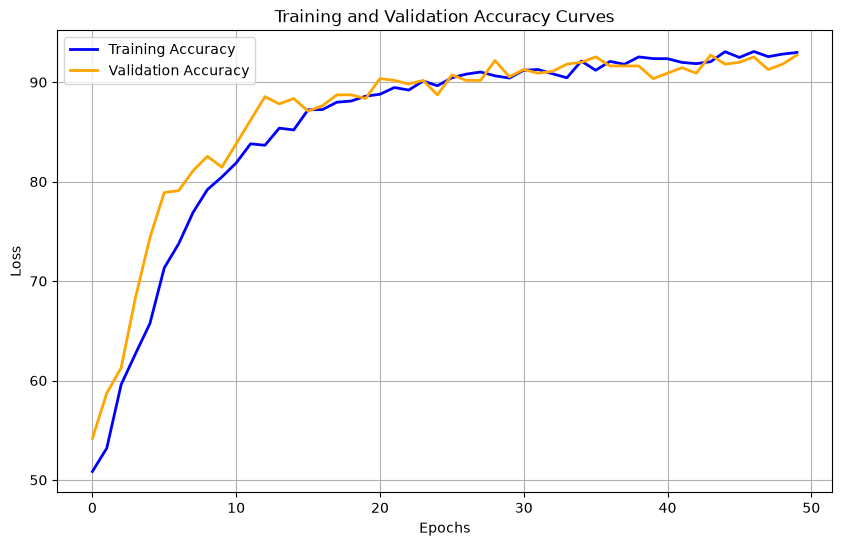

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(acc_val, label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()